# 01_B - Preprocessing sensitivity of O-information

Exhaustively evaluate **orders 3 and 4 only** under six preprocessing versions.
Save every scan-level Omega and separate C-positive / NR-positive average precision
(PR-AUC) for MA, DBS and their pooled scans. Each version has four figure cells below.


In [1]:
from pathlib import Path
import os
import sys

ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / 'src' / 'hoi_anesthesia').is_dir()
)
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import importlib
from datetime import datetime

import h5py
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from src.hoi_anesthesia import diagnostics as dg

importlib.reload(dg)
MAT_PATHS = {
    'MA': Path(r'C:\CAMILO\Brain_Entropy\DATA\monkeys\data_ts_Anesthesia_Cleaned.mat'),
    'DBS': Path(r'C:\CAMILO\Brain_Entropy\DATA\monkeys\data_ts_DBS_CoCoMac_0.0025-0.05_Cleaned_Camilo_version.mat'),
}
OUT = Path('results') / 'diagnostics'
OUT.mkdir(parents=True, exist_ok=True)
DATASETS = ['MA', 'DBS']
ts = {ds: dg.load_timeseries(path, ds) for ds, path in MAT_PATHS.items()}
sns.set_theme(style='whitegrid', context='notebook')


In [2]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

In [3]:
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
BATCH_SIZE = 4096
ORDERS = (3, 4)
DATASETS = ('MA', 'DBS')
VARIANTS = {
    'V0': ('Original', {}),
    'V1': ('GSR', {'gsr': True}),
    'V2': ('Duration', {'temporal': 'primary'}),
    'V3': ('Duration + GSR', {'temporal': 'primary', 'gsr': True}),
    'V4': ('Notch + GSR', {'gsr': True}),
    'V3r': ('Duration + GSR (replication)', {'temporal': 'replication', 'gsr': True}),
}
omega_path = OUT / '01_B_nplet_omega_summaries.h5'


## Preprocessing

GSR is per-region OLS on the mean z-scored regional signal, before the copula.
V4 adds a 0.0333-Hz DBS notch. Duration versions use MA first 250 / DBS even samples
(600 / 625 s); V3r uses MA last 250 / DBS odd samples. The band-pass is unchanged.


In [4]:
covs = {}
for variant, (label, options) in VARIANTS.items():
    covs[variant] = {}
    for ds in DATASETS:
        kwargs = dict(options)
        if variant == 'V4' and ds == 'DBS':
            kwargs['notch_hz'] = 1 / 30
        covs[variant][ds] = {
            state: dg.gc_covariances(np.stack([
                dg.apply_pipeline(x, ds, **kwargs) for x in scans
            ]))
            for state, scans in ts[ds].items()
        }
    if variant != 'V0':
        dg.save_covariance_h5(
            OUT / f'01_B_covariance_matrices_gc_{variant}.h5', covs[variant],
        )


## Exhaustive calculation and saving

C = MA/DBS awake. NR = MA ketamine, deep propofol, sevo4; DBS off, VT low/high.
Other states are saved but excluded from class scores. For each of the 88,560 triplets
and 1,749,060 quadruplets, save all scan values, mean C-minus-NR delta, and two PR-AUCs
using the same Omega score with C or NR as positive.

Combined scores use pooled MA+DBS scans, not averages of dataset scores; combined delta
is pooled mean C minus pooled mean NR. All scores are written during batch calculation.
Batches stream into compressed HDF5 (~24 GB before compression); this cell recreates the file.


In [5]:
import gc

with h5py.File(omega_path, 'w') as h5:
    h5.attrs['omega_axes'] = 'scan, n-plet'
    h5.attrs['region_indices'] = 'zero-based; nplets rows identify omega columns'
    h5.attrs['pr_auc'] = 'average precision; higher Omega; positive class C or NR'
    h5.attrs['delta'] = 'mean C minus mean NR; combined uses pooled scans'
    h5.attrs['generated'] = datetime.now().isoformat(timespec='seconds')
    metadata = {}
    for ds in DATASETS:
        rows = [
            (ds, state, dg.state_class(ds, state), i)
            for state, scans in covs['V0'][ds].items() for i in range(len(scans))
        ]
        metadata[ds] = pd.DataFrame(rows, columns=['dataset', 'state', 'class', 'scan_index'])
    metadata['combined'] = pd.concat(
        [metadata[ds] for ds in DATASETS], ignore_index=True,
    )
    for ds, frame in metadata.items():
        group = h5.create_group(f'scans/{ds}')
        for column in ('dataset', 'state', 'class'):
            group.create_dataset(
                column, data=np.asarray(frame[column], dtype=h5py.string_dtype()),
            )
        group.create_dataset('scan_index', data=frame.scan_index.to_numpy())
    labels = {
        ds: np.where(frame['class'] == 'C', 1, np.where(frame['class'] == 'NR', 0, -1))
        for ds, frame in metadata.items() if ds != 'combined'
    }
    for variant in VARIANTS:
        X = {
            ds: np.concatenate(list(covs[variant][ds].values()), axis=0)
            for ds in DATASETS
        }
        variant_group = h5.create_group(variant)
        for order in ORDERS:
            try:
                dg.save_exhaustive_comparison(
                    X, labels, order, variant_group,
                    batch_size=BATCH_SIZE, device=DEVICE,
                )
            finally:
                gc.collect()
                if torch.device(DEVICE).type == 'cuda':
                    with torch.cuda.device(DEVICE):
                        torch.cuda.empty_cache()
                    live = torch.cuda.memory_allocated(DEVICE) / 2**30
                    reserved = torch.cuda.memory_reserved(DEVICE) / 2**30
                    print(f'{variant}/n={order}: GPU after cleanup '
                          f'live={live:.2f} GiB, reserved={reserved:.2f} GiB')
        del X


V0/n=3: GPU after cleanup live=0.01 GiB, reserved=2.07 GiB


V0/n=4: GPU after cleanup live=0.25 GiB, reserved=2.07 GiB


KeyboardInterrupt: 

## Plots from saved values

Run the setup below, then any individual figure cell; no Omega recalculation is needed.
State violins use **every scan/n-plet value** via a chunked, 1,024-bin Gaussian density
estimate, with no subsampling. Each violin is normalised independently.
Selected-n-plet figures use every C/NR scan for the two PR-AUC maxima, not minimum PR-AUC.
Selection is performed afterward from saved scores; these are descriptive, in-sample selections.


In [ ]:
from pathlib import Path
import importlib

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from src.hoi_anesthesia import diagnostics as dg

importlib.reload(dg)
omega_path = Path('results') / 'diagnostics' / '01_B_nplet_omega_summaries.h5'
PLOT_LABELS = {
    'V0': 'Original', 'V1': 'GSR', 'V2': 'Duration',
    'V3': 'Duration + GSR', 'V4': 'Notch + GSR',
    'V3r': 'Duration + GSR (replication)',
}
CLASS_PALETTE = {'C': '#FF9900', 'NR': '#9C7AD8', 'descriptive': '#9E9E9E'}


In [ ]:
def plot_all_states(variant):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    with h5py.File(omega_path, 'r') as h5:
        for row, ds in enumerate(('MA', 'DBS')):
            states = h5[f'scans/{ds}/state'].asstr()[:]
            classes = h5[f'scans/{ds}/class'].asstr()[:]
            state_order = list(dict.fromkeys(states))
            for col, order in enumerate((3, 4)):
                ax = axes[row, col]
                omega = h5[f'{variant}/{ds}/{order}/omega']
                for position, state in enumerate(state_order):
                    scans = np.flatnonzero(states == state)
                    result = dg.saved_omega_density(omega, scans)
                    width = 0.4 * result['density'] / result['density'].max()
                    ax.fill_betweenx(
                        result['coords'], position - width, position + width,
                        facecolor=CLASS_PALETTE[classes[scans[0]]],
                        edgecolor='black', linewidth=0.5, alpha=0.8,
                    )
                ax.axhline(0, color='grey', linestyle=':', linewidth=1)
                ax.set_xticks(
                    range(len(state_order)), [dg.PRETTY_LABELS[s] for s in state_order],
                    rotation=30, ha='right',
                )
                ax.set(title=f'{ds}, order {order}', ylabel='Scan-level $\\Omega$')
    fig.suptitle(f'{variant}: {PLOT_LABELS[variant]} - all n-plets, by state')
    fig.tight_layout()
    fig.savefig(omega_path.parent / f'01_B_fig_{variant}_all_states.png', dpi=150)
    plt.show()


In [ ]:
def plot_selected_nplets(variant, source):
    fig, axes = plt.subplots(2, 2, figsize=(10, 7.5))
    selected = []
    with h5py.File(omega_path, 'r') as h5:
        for row, order in enumerate((3, 4)):
            scores = h5[f'{variant}/{source}/{order}']
            for col, positive in enumerate(('C', 'NR')):
                ap = scores[f'pr_auc_{positive}'][:]
                index = int(np.argmax(ap))
                nplet = scores['nplets'][index].tolist()
                frames = []
                for ds in (('MA', 'DBS') if source == 'combined' else (source,)):
                    classes = h5[f'scans/{ds}/class'].asstr()[:]
                    omega = h5[f'{variant}/{ds}/{order}/omega'][:, index]
                    mask = classes != 'descriptive'
                    frames.append(pd.DataFrame({
                        'dataset': ds, 'class': classes[mask], 'omega': omega[mask],
                    }))
                frame = pd.concat(frames, ignore_index=True)
                ax = axes[row, col]
                sns.violinplot(
                    data=frame, x='class', y='omega', hue='class',
                    order=['C', 'NR'], palette=CLASS_PALETTE,
                    inner='box', cut=0, legend=False, ax=ax,
                )
                sns.stripplot(
                    data=frame, x='class', y='omega', order=['C', 'NR'],
                    color='black', size=2, alpha=0.5, jitter=False, ax=ax,
                )
                chance = scores.attrs[f'chance_pr_auc_{positive}']
                ax.set(
                    title=f'Order {order}, {positive}-positive: AP={ap[index]:.3f} '
                          f'(chance {chance:.3f})\nRegions {nplet}',
                    xlabel='', ylabel='Scan-level $\\Omega$',
                )
                selected.append({
                    'variant': variant, 'source': source, 'order': order,
                    'positive_class': positive, 'pr_auc': ap[index],
                    'chance': chance, 'delta': scores['delta'][index], 'nplet': nplet,
                })
    fig.suptitle(f'{variant}: {PLOT_LABELS[variant]} - {source} PR-AUC selections')
    fig.tight_layout()
    fig.savefig(omega_path.parent / f'01_B_fig_{variant}_selected_{source}.png', dpi=150)
    pd.DataFrame(selected).to_csv(
        omega_path.parent / f'01_B_selected_{variant}_{source}.csv', index=False,
    )
    plt.show()


### V0 - Original


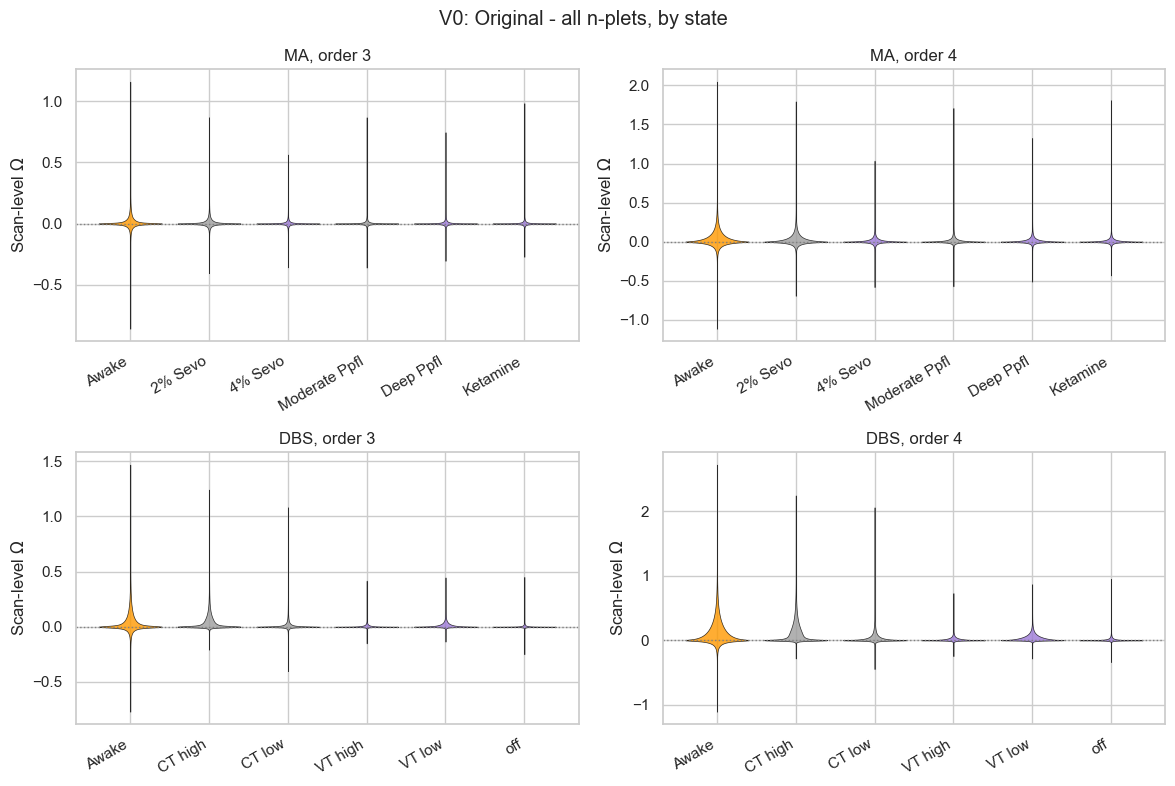

In [ ]:
plot_all_states('V0')


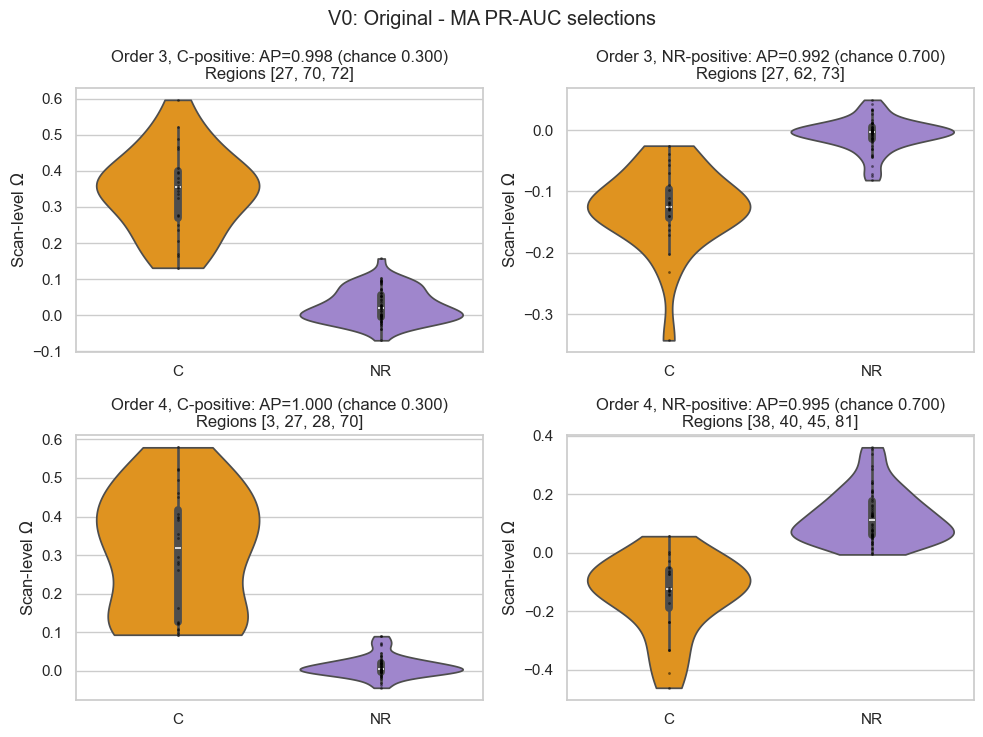

In [ ]:
plot_selected_nplets('V0', 'MA')


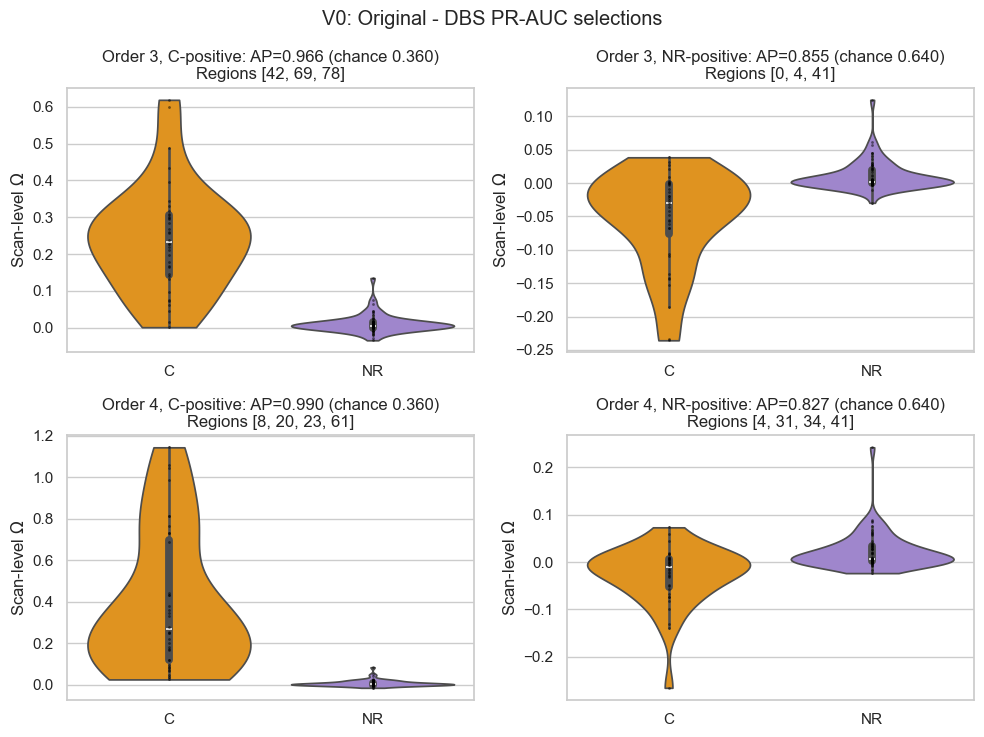

In [ ]:
plot_selected_nplets('V0', 'DBS')


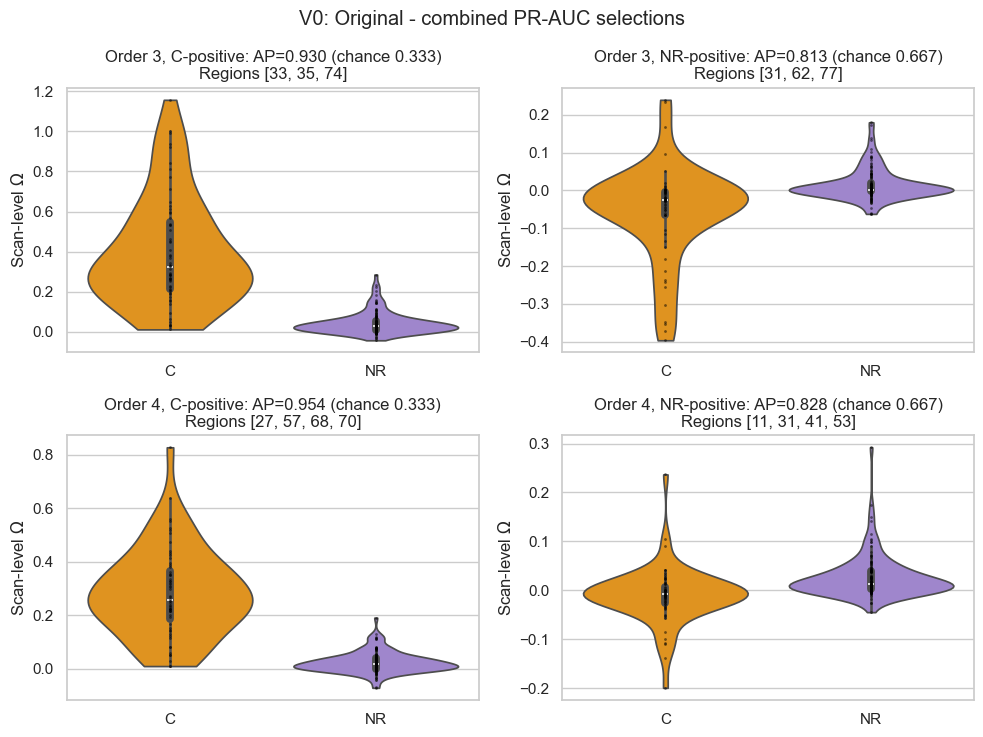

In [ ]:
plot_selected_nplets('V0', 'combined')


### V1 - GSR


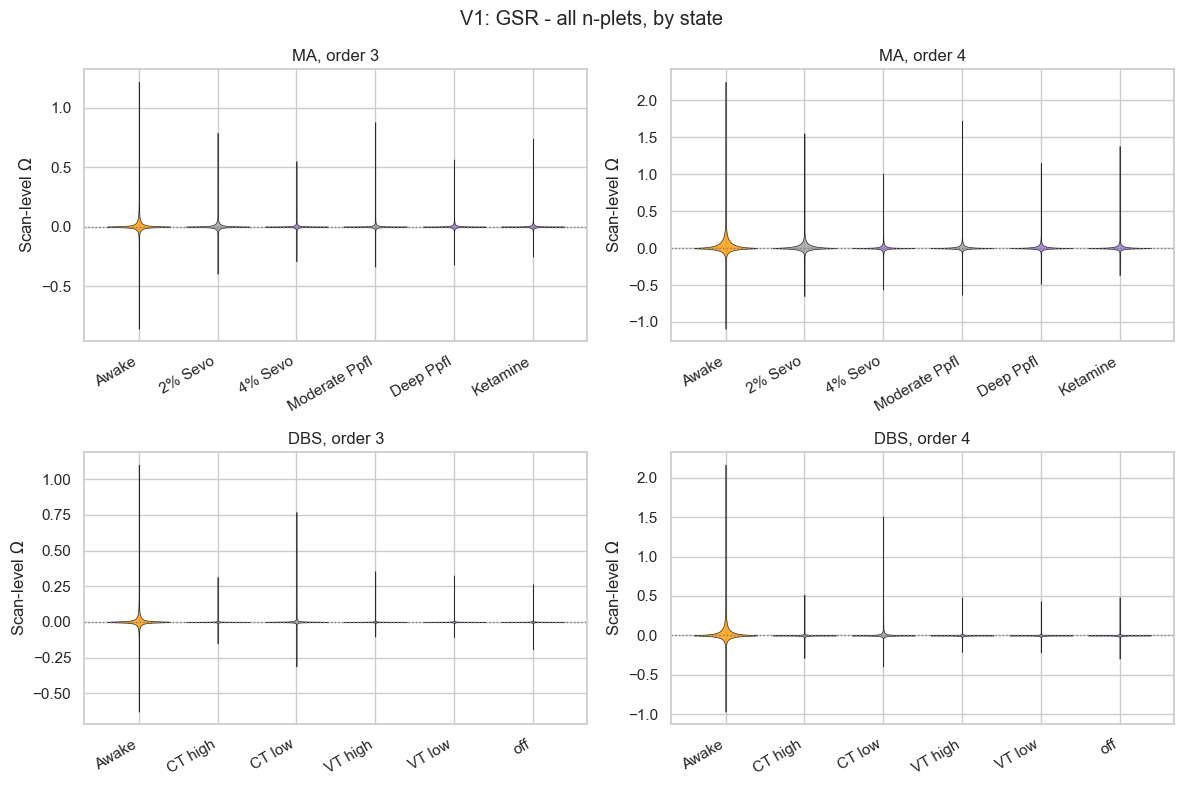

In [ ]:
plot_all_states('V1')


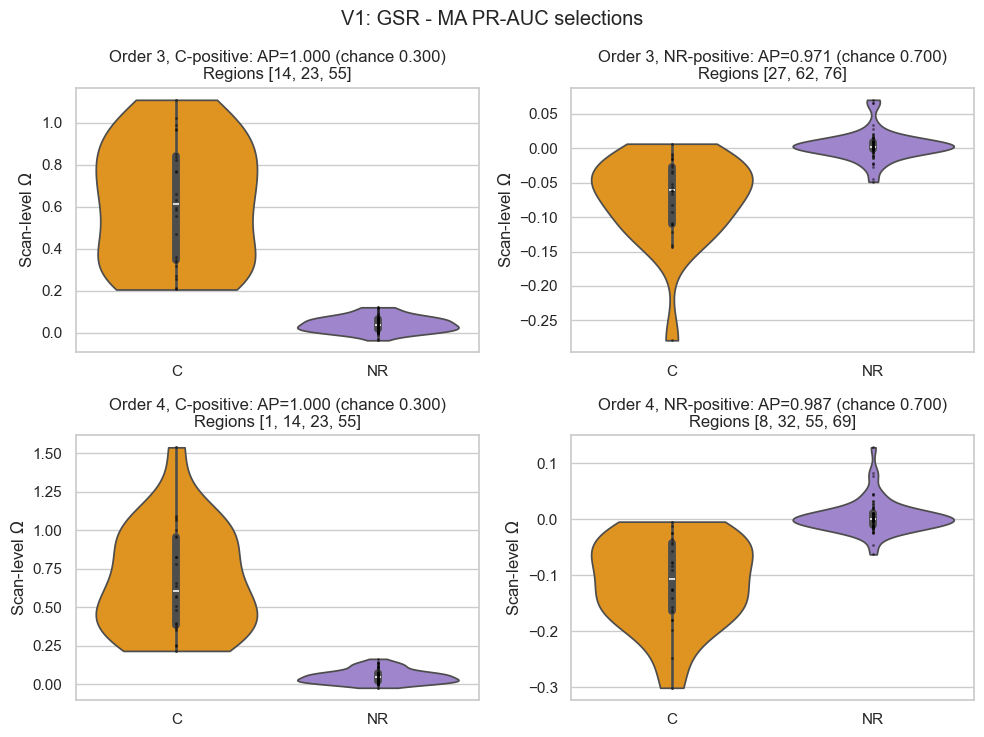

In [ ]:
plot_selected_nplets('V1', 'MA')


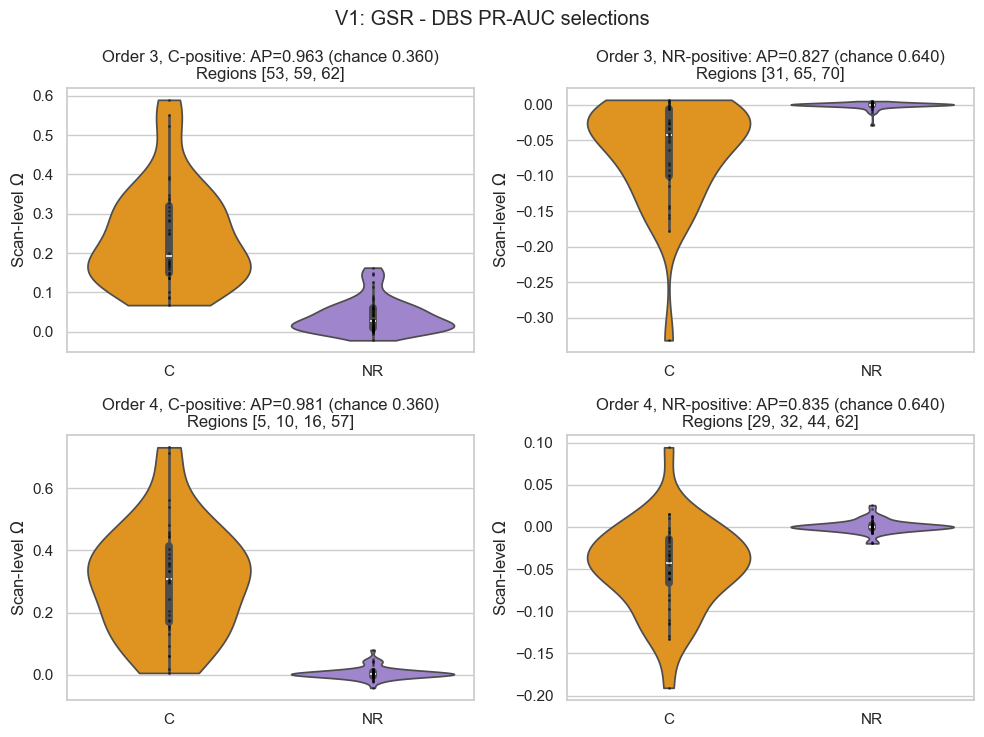

In [ ]:
plot_selected_nplets('V1', 'DBS')


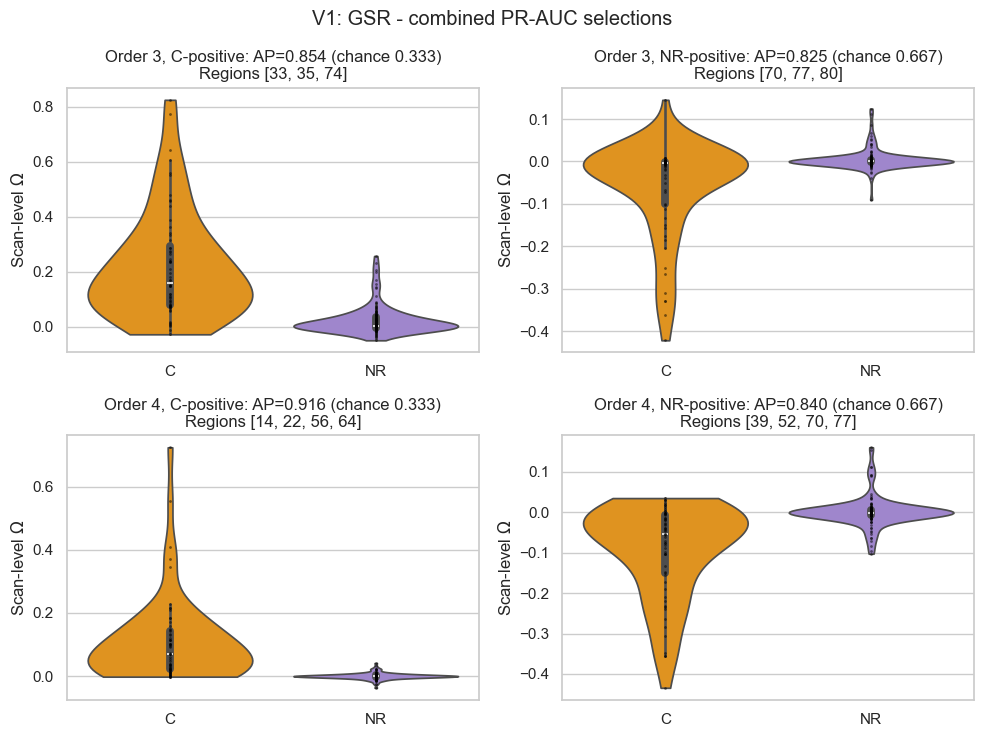

In [ ]:
plot_selected_nplets('V1', 'combined')


### V2 - Duration


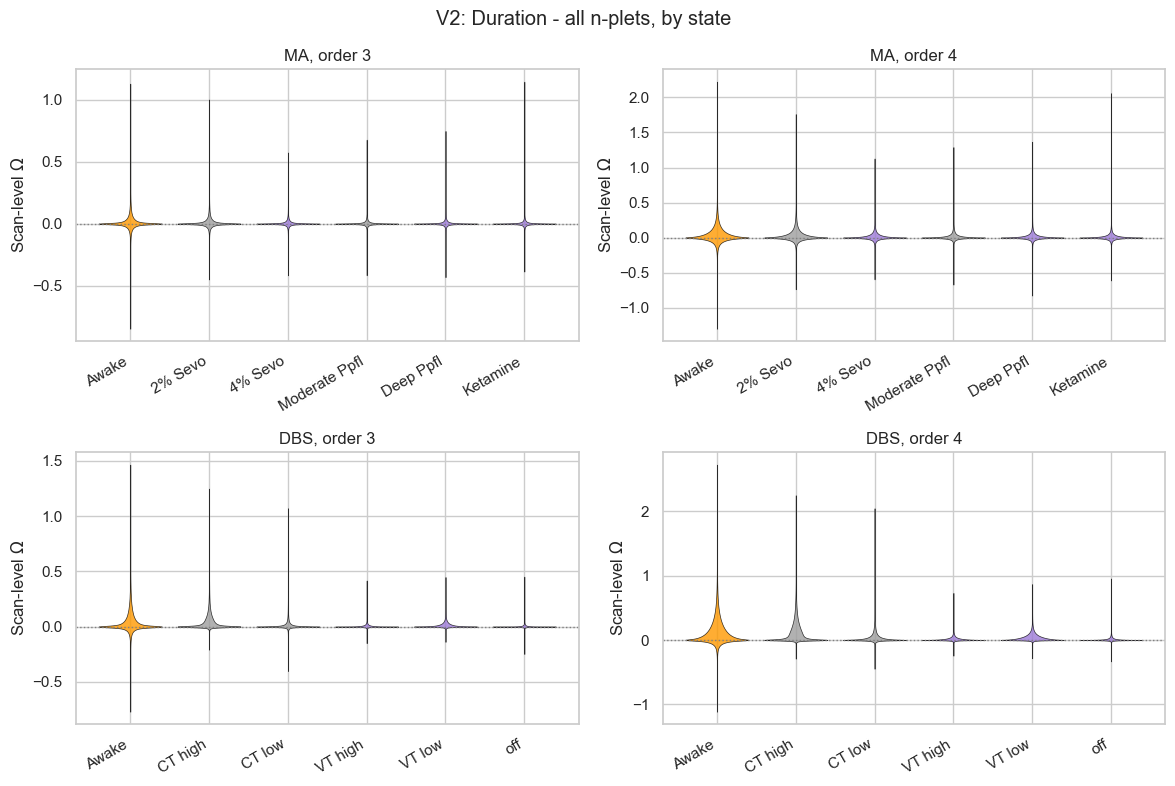

In [ ]:
plot_all_states('V2')


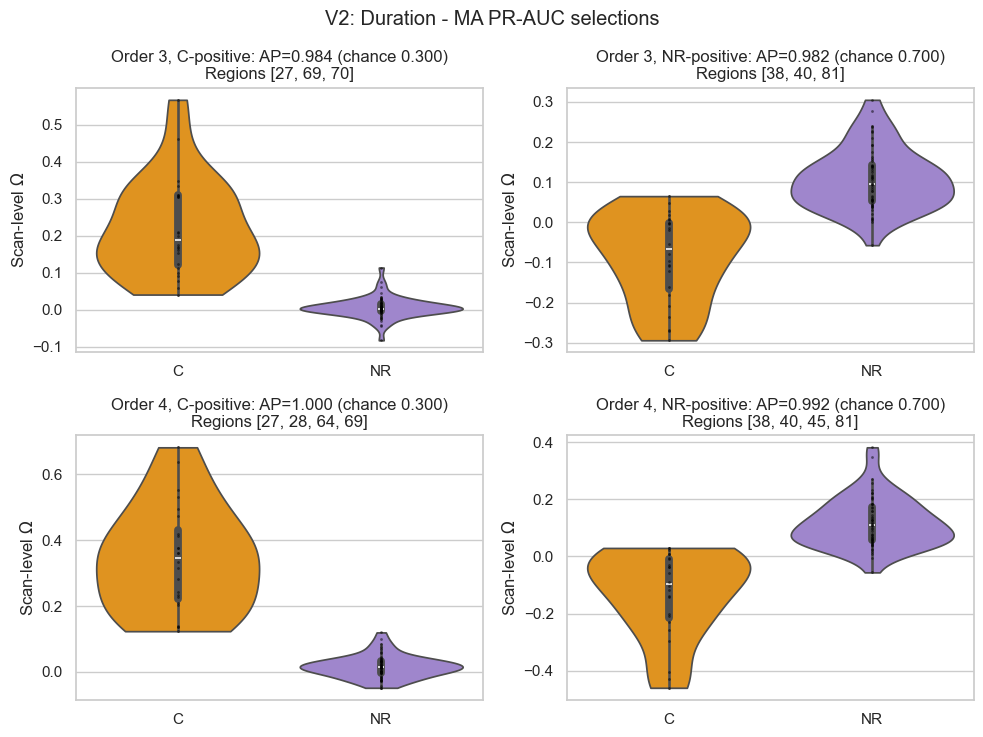

In [ ]:
plot_selected_nplets('V2', 'MA')


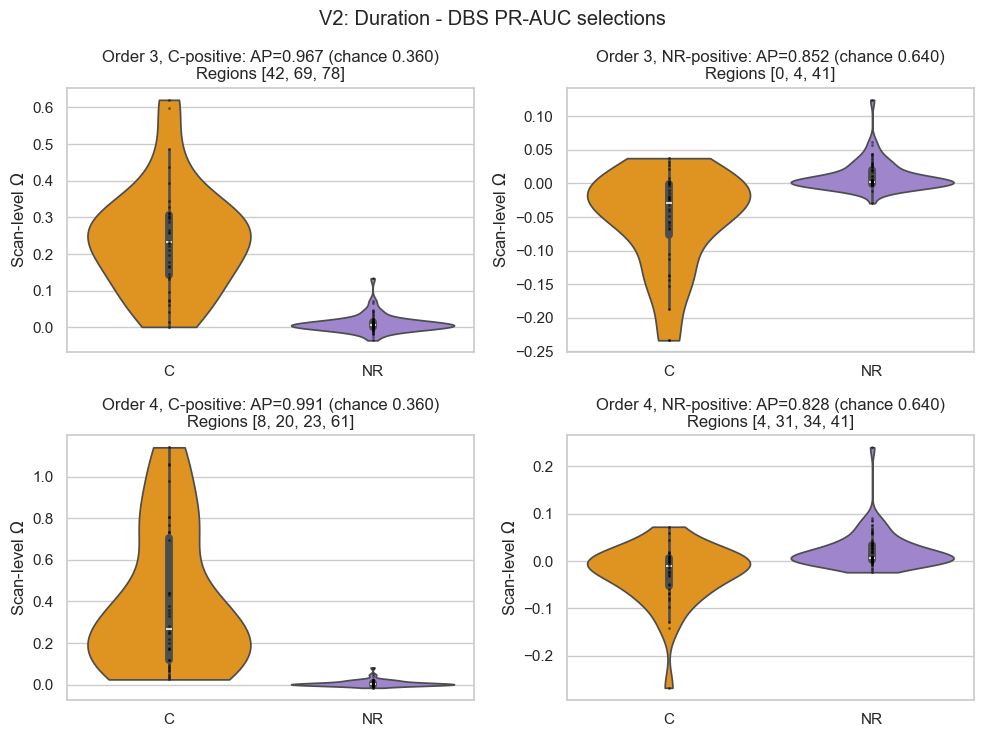

In [ ]:
plot_selected_nplets('V2', 'DBS')


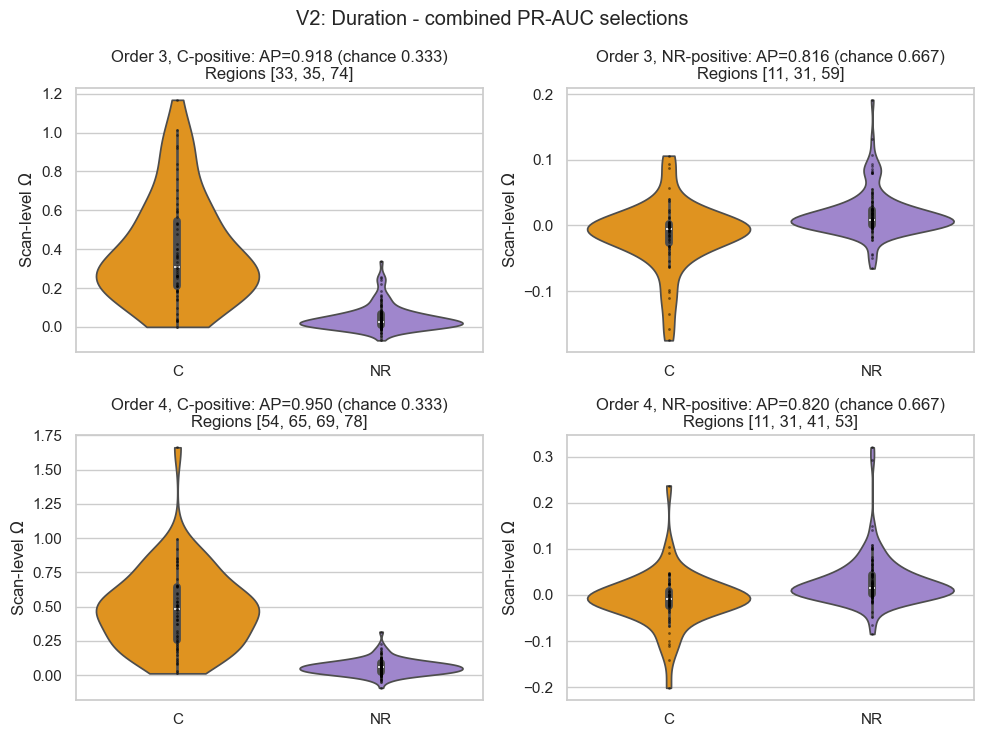

In [ ]:
plot_selected_nplets('V2', 'combined')


### V3 - Duration + GSR


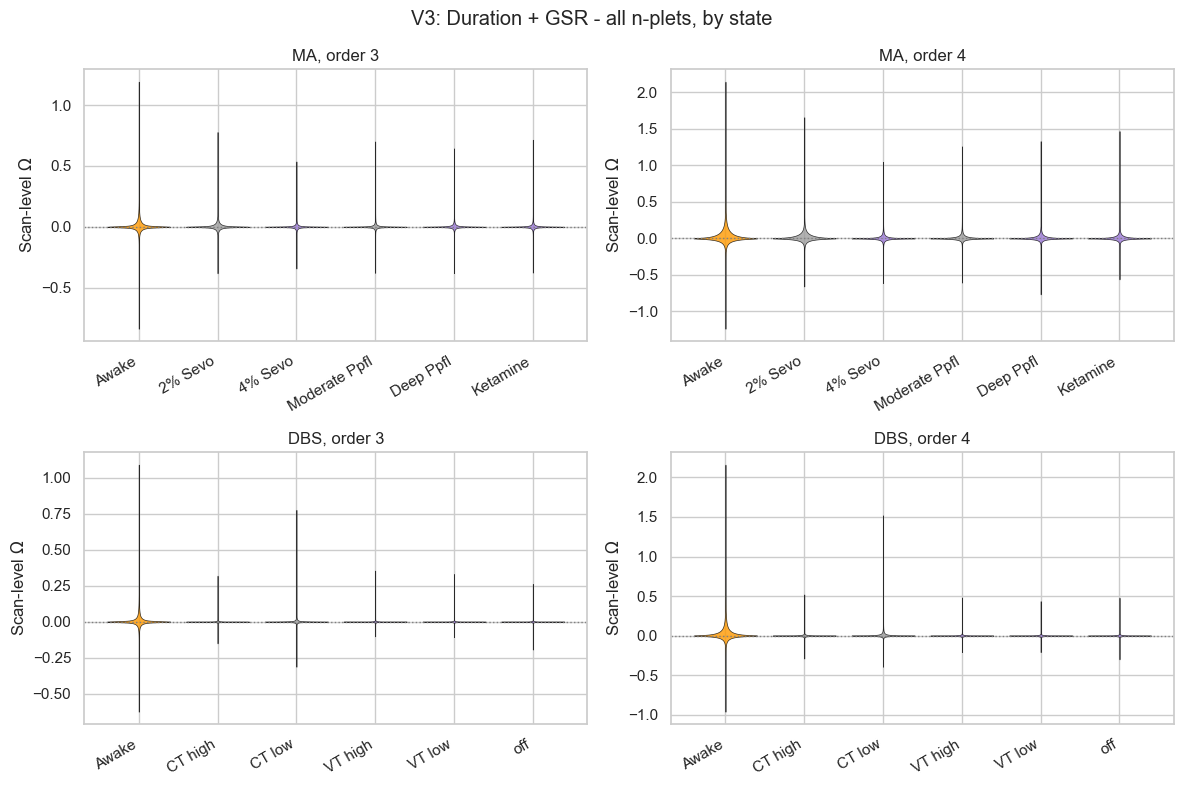

In [ ]:
plot_all_states('V3')


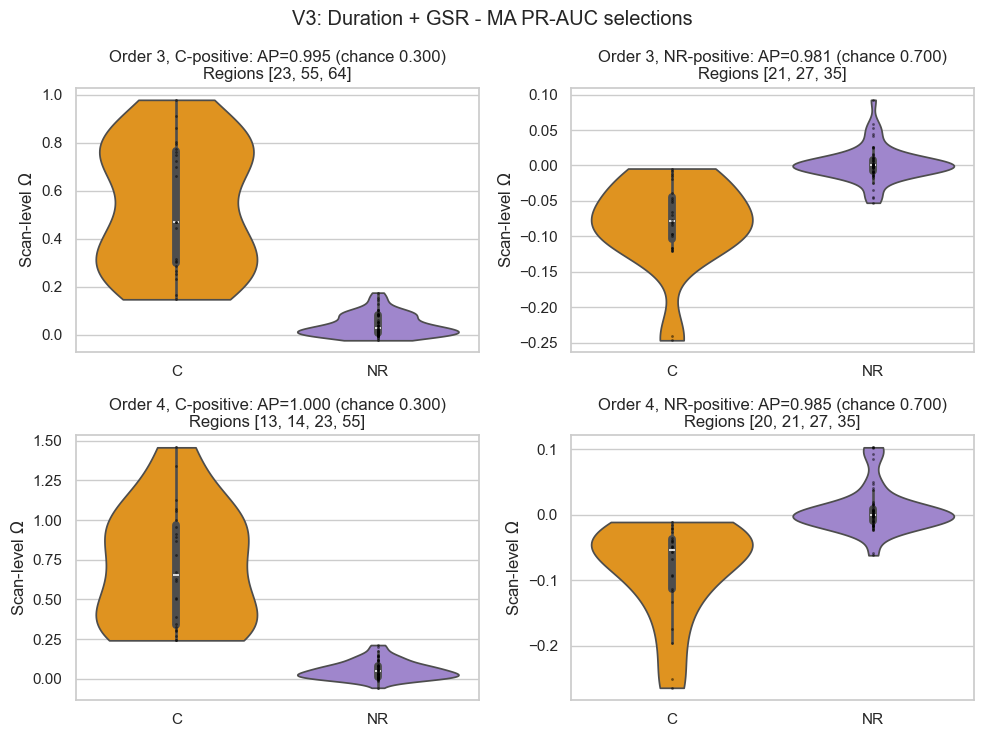

In [ ]:
plot_selected_nplets('V3', 'MA')


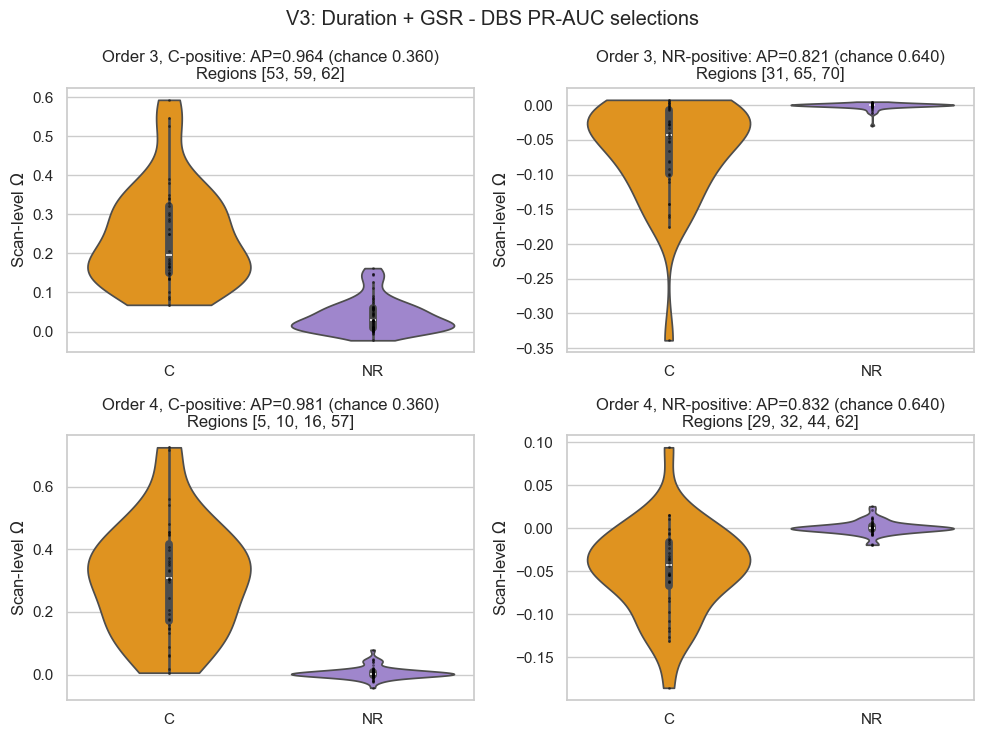

In [ ]:
plot_selected_nplets('V3', 'DBS')


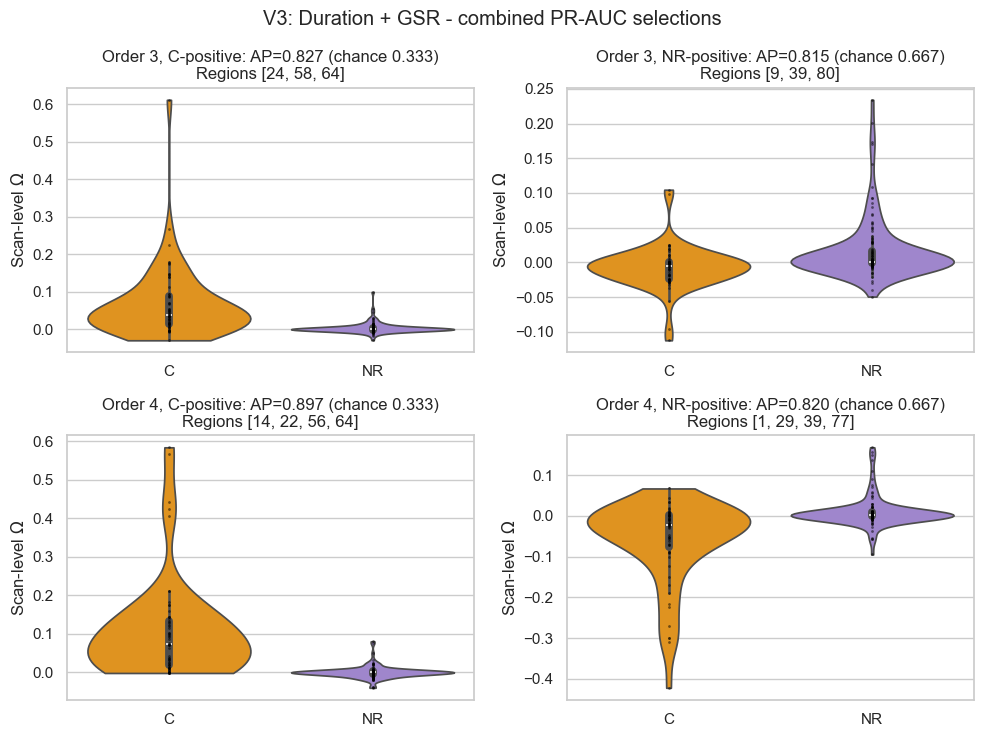

In [ ]:
plot_selected_nplets('V3', 'combined')


### V4 - Notch + GSR


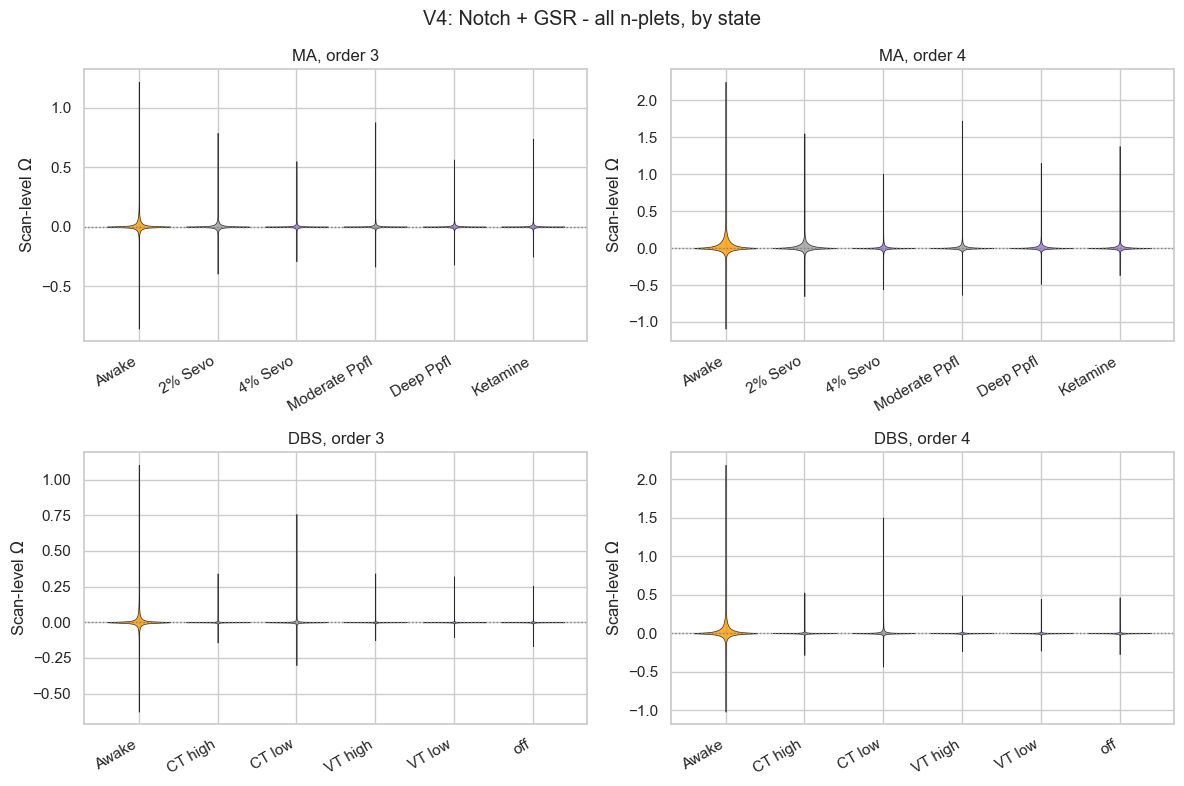

In [ ]:
plot_all_states('V4')


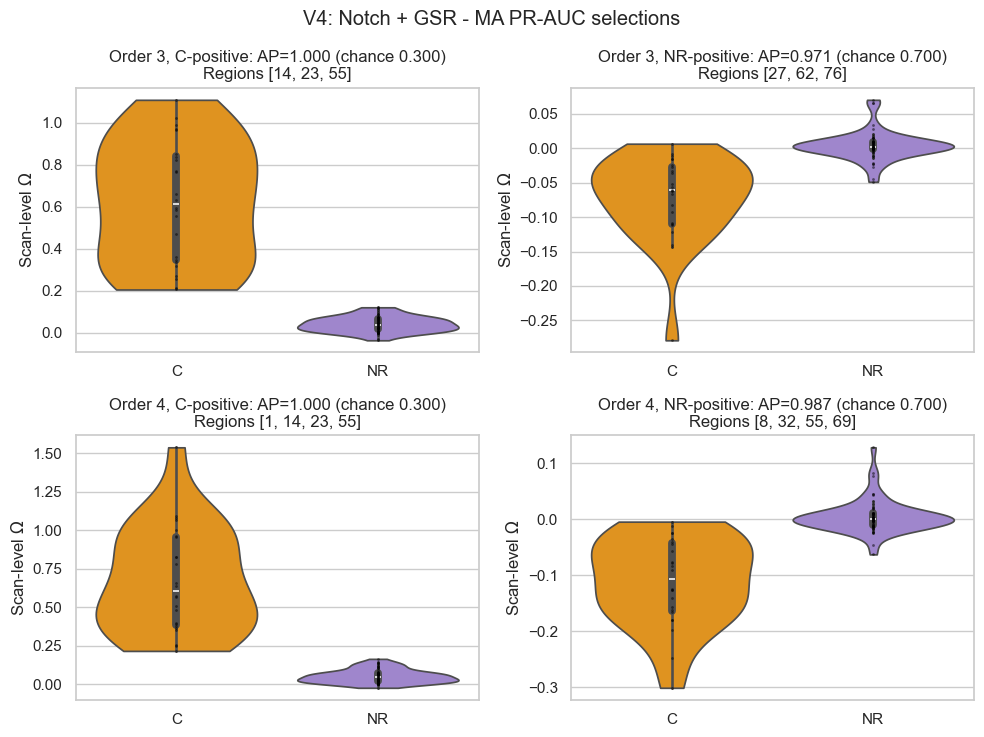

In [ ]:
plot_selected_nplets('V4', 'MA')


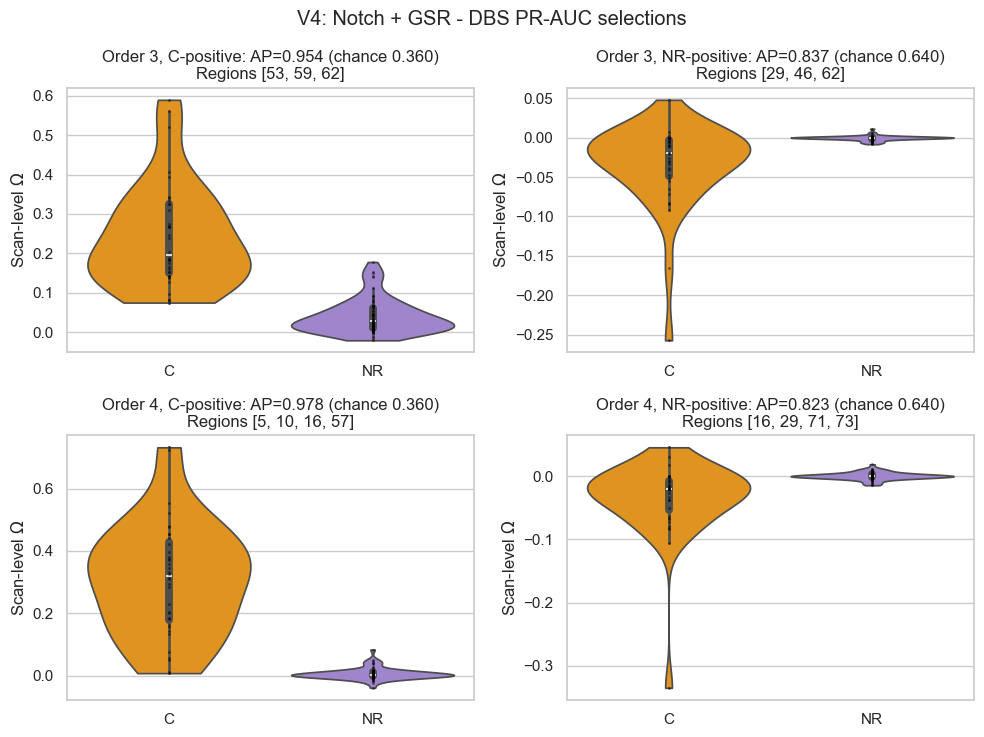

In [ ]:
plot_selected_nplets('V4', 'DBS')


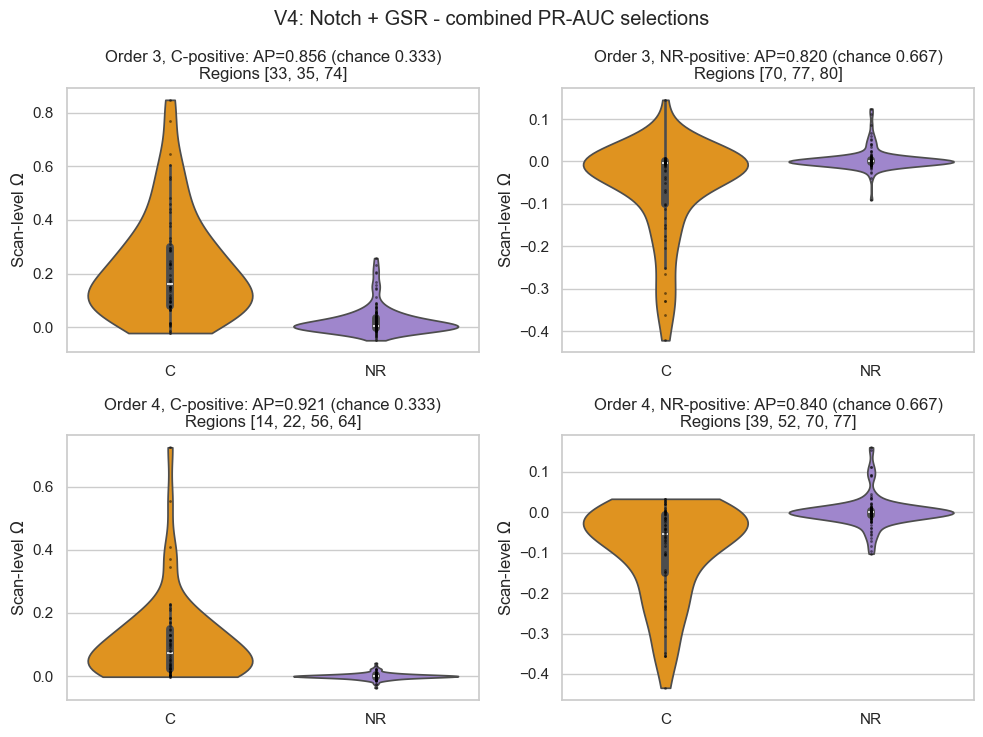

In [ ]:
plot_selected_nplets('V4', 'combined')


### V3r - Duration + GSR (replication)


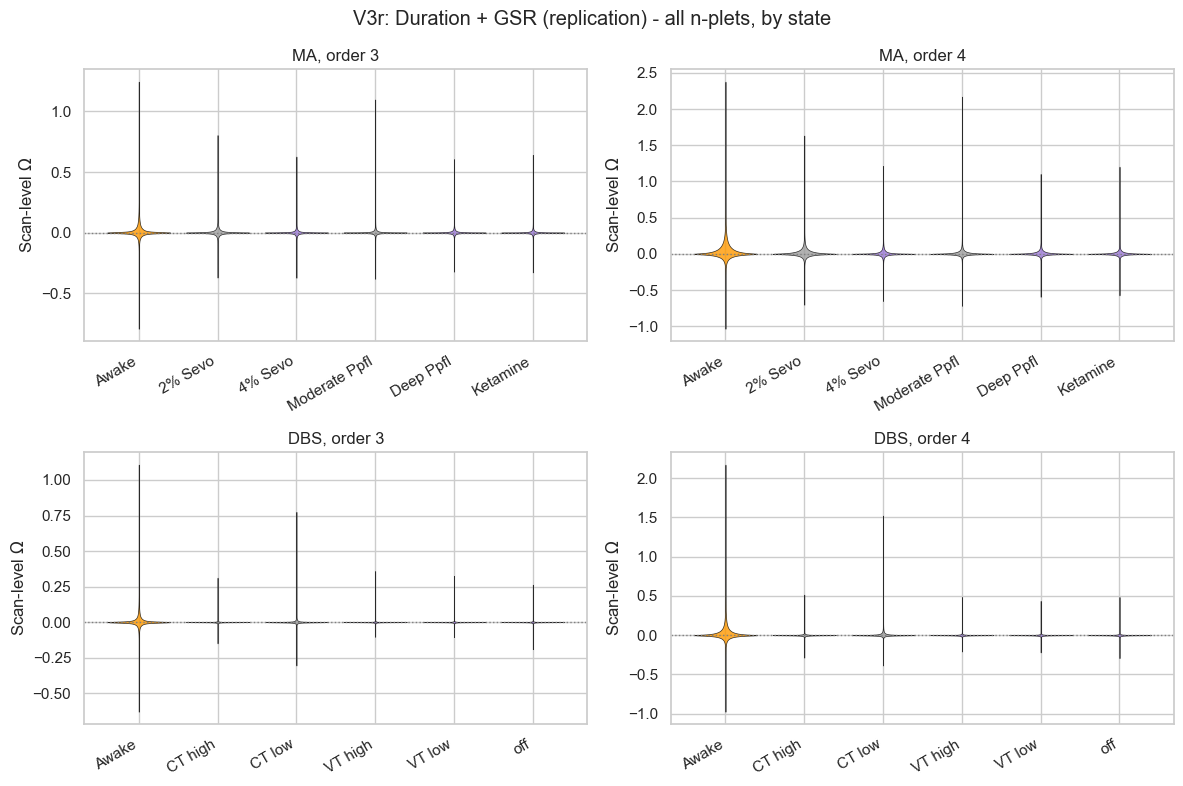

In [ ]:
plot_all_states('V3r')


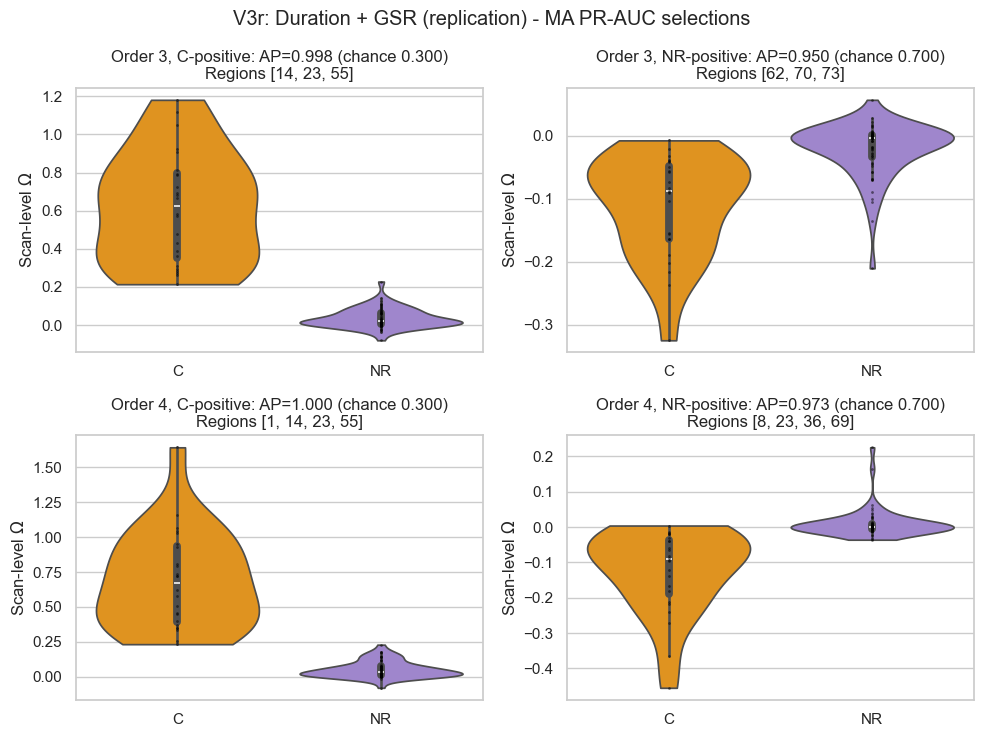

In [ ]:
plot_selected_nplets('V3r', 'MA')


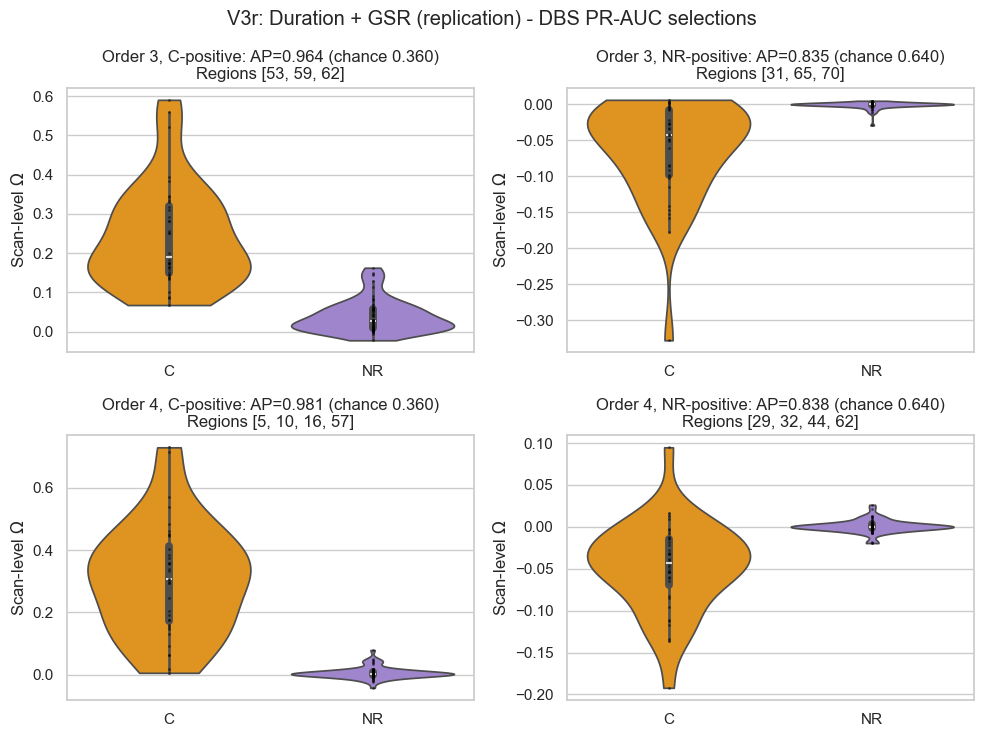

In [ ]:
plot_selected_nplets('V3r', 'DBS')


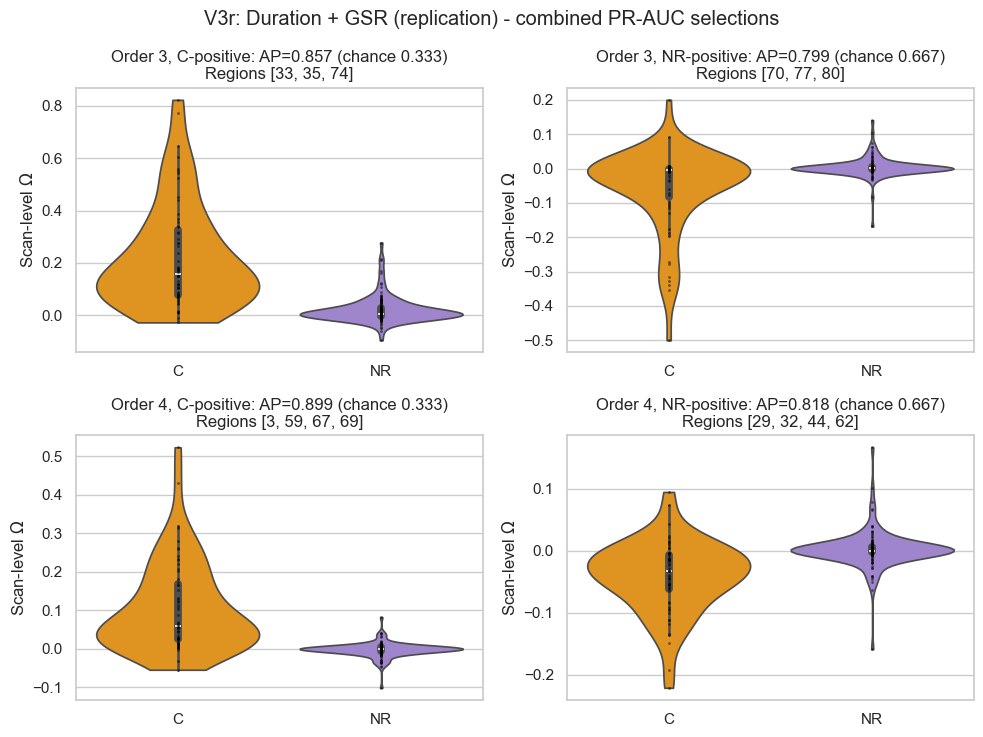

In [ ]:
plot_selected_nplets('V3r', 'combined')


**Previous diagnostics:** GSR changed Omega signs, regional rankings and some fixed-n-plet
discrimination; duration-only and notch effects were smaller. The exhaustive PR-AUC selections
and pooled distributions above are new results; no conclusion about their performance is assumed.


In [6]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

## Best PR-AUC by preprocessing

Compare the maximum saved PR-AUC across versions for each dataset, order and positive class.
Exact ties are retained. These are in-sample, selected maxima, not held-out performance or
an independent justification for choosing preprocessing.


In [ ]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
from IPython.display import display

omega_path = Path('results') / 'diagnostics' / '01_B_nplet_omega_summaries.h5'
preprocessing_labels = {
    'V0': 'Original', 'V1': 'GSR', 'V2': 'Duration',
    'V3': 'Duration + GSR', 'V4': 'Notch + GSR',
    'V3r': 'Duration + GSR (replication)',
}
comparison_rows = []
with h5py.File(omega_path, 'r') as h5:
    for dataset in ('MA', 'DBS', 'combined'):
        for order in (3, 4):
            for positive in ('C', 'NR'):
                for version, label in preprocessing_labels.items():
                    group = h5[f'{version}/{dataset}/{order}']
                    scores = group[f'pr_auc_{positive}'][:]
                    index = int(np.argmax(scores))
                    comparison_rows.append({
                        'dataset': dataset, 'order': order, 'positive_class': positive,
                        'version': version, 'preprocessing': label, 'PR_AUC': scores[index],
                        'chance': group.attrs[f'chance_pr_auc_{positive}'],
                        'nplet': group['nplets'][index].tolist(),
                    })
preprocessing_comparison = pd.DataFrame(comparison_rows)
keys = ['dataset', 'order', 'positive_class']
best_scores = preprocessing_comparison.groupby(keys, sort=False).PR_AUC.transform('max')
best_preprocessing = preprocessing_comparison[
    preprocessing_comparison.PR_AUC == best_scores
].reset_index(drop=True)
preprocessing_comparison.to_csv(
    omega_path.parent / '01_B_preprocessing_pr_auc_comparison.csv', index=False,
)
best_preprocessing.to_csv(
    omega_path.parent / '01_B_best_preprocessing_pr_auc.csv', index=False,
)
from IPython.display import Markdown

for positive in ('C', 'NR'):
    display(Markdown(f'### Best preprocessing: {positive}-positive task'))
    winners = best_preprocessing[best_preprocessing.positive_class == positive]
    display(winners.style.format({
        'PR_AUC': '{:.6f}', 'chance': '{:.3f}',
    }).hide(axis='index'))


### Best preprocessing: C-positive task

dataset,order,positive_class,version,preprocessing,PR_AUC,chance,nplet
MA,3,C,V1,GSR,1.000000,0.300,"[14, 23, 55]"
MA,3,C,V4,Notch + GSR,1.000000,0.300,"[14, 23, 55]"
MA,4,C,V0,Original,1.000000,0.300,"[3, 27, 28, 70]"
MA,4,C,V1,GSR,1.000000,0.300,"[1, 14, 23, 55]"
MA,4,C,V2,Duration,1.000000,0.300,"[27, 28, 64, 69]"
MA,4,C,V3,Duration + GSR,1.000000,0.300,"[13, 14, 23, 55]"
MA,4,C,V4,Notch + GSR,1.000000,0.300,"[1, 14, 23, 55]"
MA,4,C,V3r,Duration + GSR (replication),1.000000,0.300,"[1, 14, 23, 55]"
DBS,3,C,V2,Duration,0.966586,0.360,"[42, 69, 78]"
DBS,4,C,V2,Duration,0.990959,0.360,"[8, 20, 23, 61]"


### Best preprocessing: NR-positive task

dataset,order,positive_class,version,preprocessing,PR_AUC,chance,nplet
MA,3,NR,V0,Original,0.991538,0.700,"[27, 62, 73]"
MA,4,NR,V0,Original,0.994521,0.700,"[38, 40, 45, 81]"
DBS,3,NR,V0,Original,0.854541,0.640,"[0, 4, 41]"
DBS,4,NR,V3r,Duration + GSR (replication),0.837822,0.640,"[29, 32, 44, 62]"
combined,3,NR,V1,GSR,0.824922,0.667,"[70, 77, 80]"
combined,4,NR,V4,Notch + GSR,0.840464,0.667,"[39, 52, 70, 77]"
